# Notebook 02: Exploratory Data Analysis

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/listings_clean.csv")
df.shape

(8075, 90)

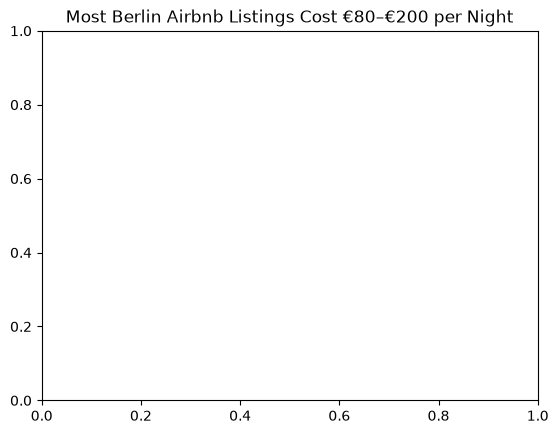

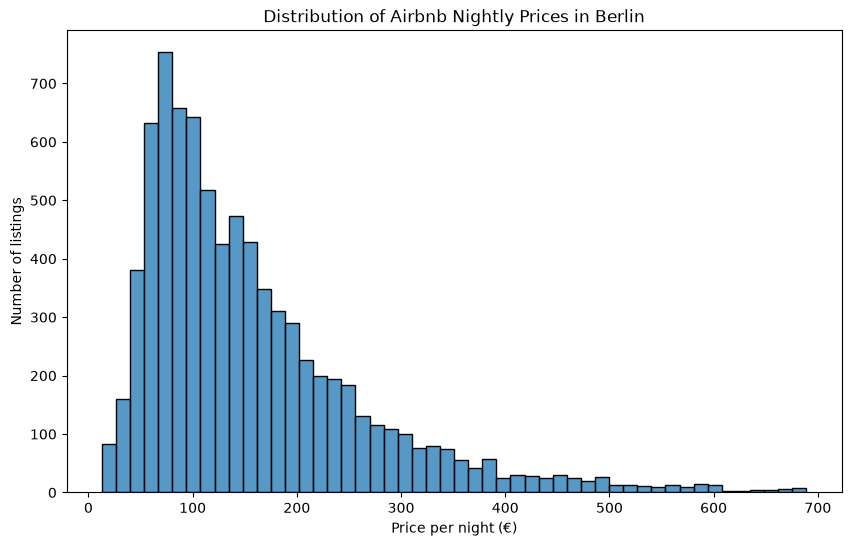

In [5]:
plt.title("Most Berlin Airbnb Listings Cost €80–€200 per Night")
plt.figure(figsize=(10, 6))
sns.histplot(df["price"], bins=50)
plt.title("Distribution of Airbnb Nightly Prices in Berlin")
plt.xlabel("Price per night (€)")
plt.ylabel("Number of listings")
plt.savefig("../images/01_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

- Most listings are priced around €75–80, which is the most common price range.
- The distribution has a long tail to the right, meaning that most listings are
  cheap or mid-priced, while only a few are very expensive.
- This confirms that most Berlin listings cost between €80 and €200 per night,
  while only a small number of listings are priced above €400.

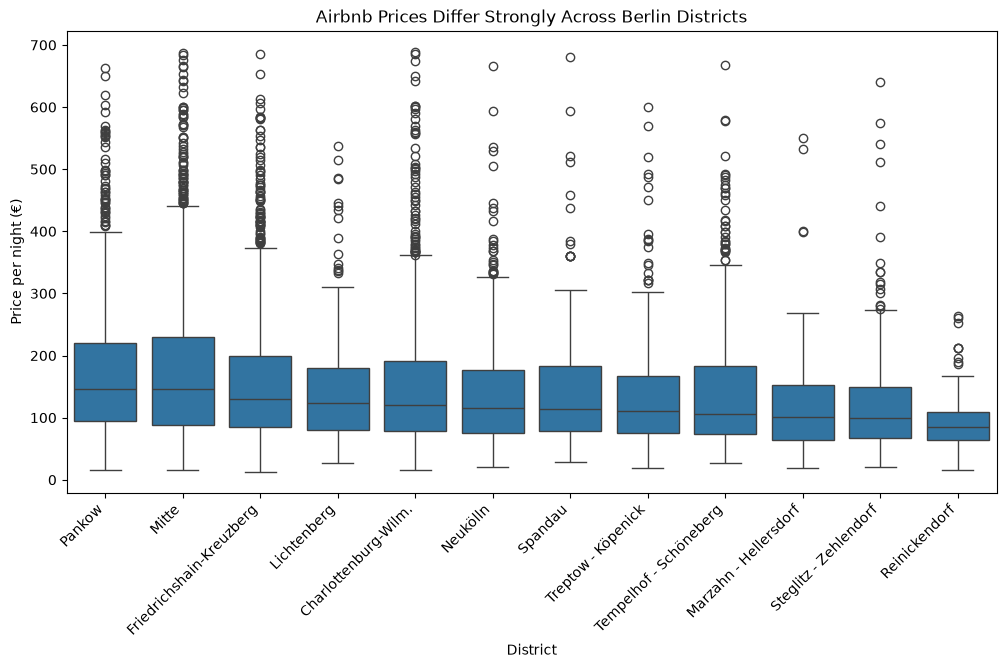

In [6]:
order = df.groupby("neighbourhood_group_cleansed")["price"].median().sort_values(ascending=False).index
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="neighbourhood_group_cleansed", y="price", order=order)
plt.title("Airbnb Prices Differ Strongly Across Berlin Districts")
plt.xlabel("District")
plt.ylabel("Price per night (€)")
plt.xticks(rotation=45, ha="right")
plt.savefig("../images/02_price_by_district.png", dpi=150, bbox_inches="tight")
plt.show()

- The most expensive districts are Pankow and Mitte (median about €145–150),
  while the cheapest is Reinickendorf (median about €85).
- Pankow's high prices may be explained by Prenzlauer Berg, a popular area
  with large renovated flats.
- However, the boxes overlap a lot, which shows that location alone does not
  explain price, so other factors such as room type, size and reviews must
  also matter.

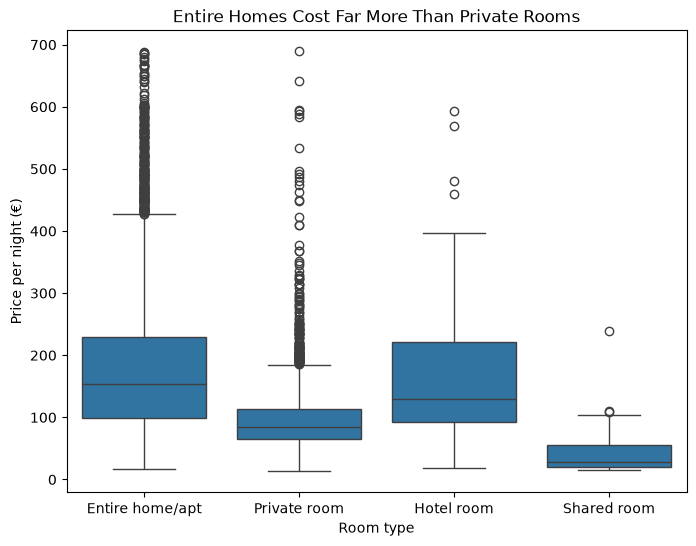

In [7]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="room_type", y="price")
plt.title("Entire Homes Cost Far More Than Private Rooms")
plt.xlabel("Room type")
plt.ylabel("Price per night (€)")
plt.savefig("../images/03_price_by_room_type.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
df.groupby("room_type")["price"].agg(["count", "median"])

,count,median
room_type,,
Entire home/apt,5796,154.000
Hotel room,53,130.000
Private room,2150,85.025
Shared room,76,27.500


- Entire homes have a median price of about €154, compared to about €85 for
  private rooms, so an entire home costs almost twice as much.
- Shared rooms are the cheapest (about €27.50), but hotel and shared rooms have
  only a few listings, so their results are less reliable.
- This shows that room type is one of the strongest drivers of price.

In [9]:
mitte = df[df["neighbourhood_group_cleansed"] == "Mitte"]
mitte["neighbourhood_cleansed"].value_counts()

neighbourhood_cleansed
Alexanderplatz       661
Brunnenstr. Süd      331
Brunnenstr. Nord     183
Moabit Ost           155
Moabit West          146
Wedding Zentrum      107
Regierungsviertel     96
Tiergarten Süd        94
Parkviertel           87
Osloer Straße         71
Name: count, dtype: int64

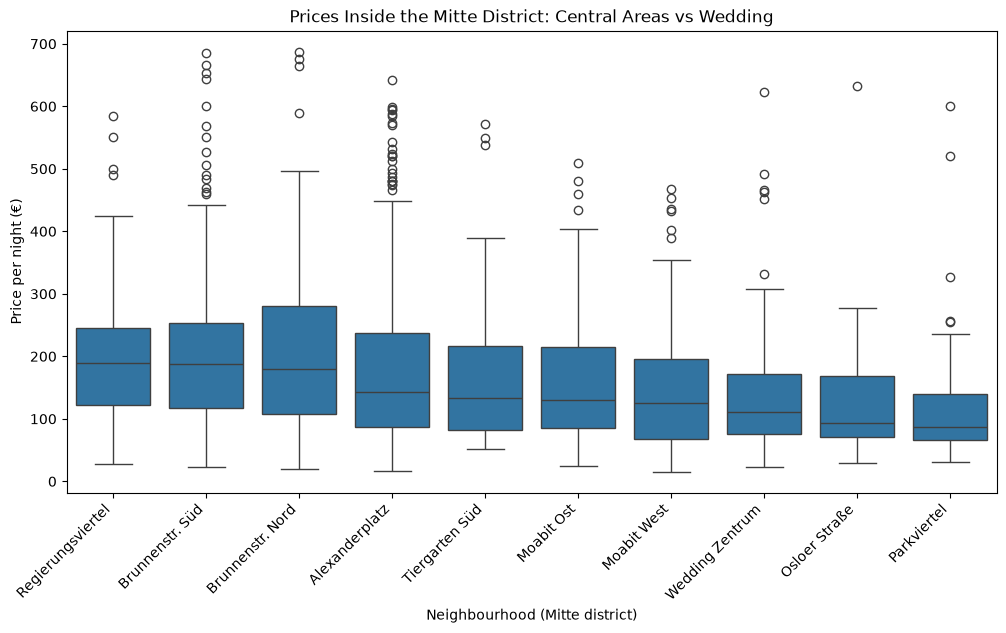

In [10]:
order = mitte.groupby("neighbourhood_cleansed")["price"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(data=mitte, x="neighbourhood_cleansed", y="price", order=order)
plt.title("Prices Inside the Mitte District: Central Areas vs Wedding")
plt.xlabel("Neighbourhood (Mitte district)")
plt.ylabel("Price per night (€)")
plt.xticks(rotation=45, ha="right")
plt.savefig("../images/04_mitte_neighbourhoods.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
mitte.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"]).sort_values("median", ascending=False)

,count,median
neighbourhood_cleansed,,
Regierungsviertel,96,188.750
Brunnenstr. Süd,331,188.330
Brunnenstr. Nord,183,179.500
Alexanderplatz,661,142.500
Tiergarten Süd,94,133.035
Moabit Ost,155,130.000
Moabit West,146,125.000
Wedding Zentrum,107,111.100
Osloer Straße,71,93.960


- Within the Mitte district, prices vary strongly: Regierungsviertel has a median
  of €189, while Parkviertel in Wedding has only €87, less than half.
- The Wedding areas (Wedding Zentrum, Osloer Straße, Parkviertel) are the
  cheapest, while central areas such as Regierungsviertel and Brunnenstr. Süd
  are the most expensive.
- Brunnenstr. Nord is an exception (€180), possibly because it borders
  Prenzlauer Berg.
- This raises the question of whether Wedding listings are cheaper because of
  their features, or whether some hosts are under-pricing them.